In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=10, suppress=False, threshold=2000)


def find_project_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "codes").is_dir() and (path / "gfn2-xtb.toml").exists():
            return path
    raise RuntimeError("Could not find project root. Run this notebook inside optxTB-MD or set PROJECT_ROOT_PATH manually.")


PROJECT_ROOT_PATH = find_project_root()
PROJECT_ROOT = str(PROJECT_ROOT_PATH)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("PROJECT_ROOT_PATH:", PROJECT_ROOT_PATH)

PROJECT_ROOT_PATH: /dss/dsshome1/09/ge45fol2/cluster_vs_pbc/optxTB-MD


In [2]:
OPTIMIZATION_RUN_ID = "nsga3_t2na_t3_efq_na_reg_216816_20260806_015821" # (E, F) with Reg for Na-O scans on top of H/O 249 (6 params + O-O scans)

RUN_OUTPUT_DIR = PROJECT_ROOT_PATH / "optimization/T_all_partial_charge_schemes/hpc_runs" / OPTIMIZATION_RUN_ID

print('Processing H/O point 249 and E, F with Reg')
point = 249
results_path = RUN_OUTPUT_DIR / f"nsga3_results_cluster_na_EFReg_{OPTIMIZATION_RUN_ID}.npz"

print(results_path)

Processing H/O point 249 and E, F with Reg
/dss/dsshome1/09/ge45fol2/cluster_vs_pbc/optxTB-MD/optimization/T_all_partial_charge_schemes/hpc_runs/nsga3_t2na_t3_efq_na_reg_216816_20260806_015821/nsga3_results_cluster_na_EFReg_nsga3_t2na_t3_efq_na_reg_216816_20260806_015821.npz


In [3]:
param_changes = {
    "kpair": {
        "Na-O": 1.0,
        "Na-H": 1.0,
    },
    "Na": {
        "slater": [0.7637870000000000, 0.5735530000000000],
        "gam": 0.2710560000000000,
        "zeff": 5.2449170000000001,
        "arep": 0.5727280000000000,
    },
}

def generate_parameter_info(param_changes, variation=0.30, kernel_abs=0.03, near_one_width=0.20, positivity_eps=1e-12, fallback_zero_abs=0.20, fixed_components=None):
    if fixed_components is None:
        fixed_components = set()

    def _percent_box(val):
        if val == 0:
            return [-fallback_zero_abs, +fallback_zero_abs]
        lo = min(val * (1 - variation), val * (1 + variation))
        hi = max(val * (1 - variation), val * (1 + variation))
        return [lo, hi]

    def _near_one_box():
        return [max(positivity_eps, 1.0 - near_one_width), 1.0 + near_one_width]

    def _make_bound(elem, key, val, idx=None):
        if key == "dkernel" and elem == "Na":
            lo, hi = -abs(kernel_abs), abs(kernel_abs)
        elif key in {"Na-O", "Na-H", "Cl-H", "Cl-O", "H-H", "O-O", "O-H"}:
            lo, hi = _near_one_box()
        elif key == "gam":
            lo, hi = _percent_box(val)
            lo = max(lo, positivity_eps)
        else:
            lo, hi = _percent_box(val)

        if not (hi > lo):
            mid = 0.5 * (lo + hi)
            tiny = max(1e-9, abs(mid) * 1e-12)
            lo, hi = mid - tiny, mid + tiny
        return [lo, hi]

    names = []
    bounds = []
    vector = []
    structure = {}
    for elem, params in param_changes.items():
        structure[elem] = {}
        for key, value in params.items():
            if isinstance(value, list):
                structure[elem][key] = []
                for i, val in enumerate(value):
                    if key == "lgam" and i == 0:
                        structure[elem][key].append("Fixing to 1.0")
                        continue
                    if (elem, key, i) in fixed_components:
                        structure[elem][key].append(("__fixed__", val))
                        continue
                    par_name = f"{elem}_{key}_{i}"
                    names.append(par_name)
                    bounds.append(_make_bound(elem, key, val, idx=i))
                    vector.append(val)
                    structure[elem][key].append(par_name)
            else:
                par_name = f"{elem}_{key}"
                names.append(par_name)
                bounds.append(_make_bound(elem, key, value))
                vector.append(value)
                structure[elem][key] = par_name
    return names, bounds, vector, structure


names, bounds, default_gfn2_vector, structure = generate_parameter_info(
    param_changes,
    fixed_components={("Na", "slater", 1)}
)
default_gfn2_vector = np.asarray(default_gfn2_vector, dtype=float)
print(names)
print(default_gfn2_vector)

['kpair_Na-O', 'kpair_Na-H', 'Na_slater_0', 'Na_gam', 'Na_zeff', 'Na_arep']
[1.       1.       0.763787 0.271056 5.244917 0.572728]


In [4]:
with np.load(results_path) as data:
    X_pareto = data["X_pareto"]
    F_pareto = data["F_pareto"]

print("X_pareto shape:", X_pareto.shape)
print("F_pareto shape:", F_pareto.shape)

X_pareto shape: (96, 6)
F_pareto shape: (96, 3)


Number of Pareto points better than GFN2-xTB: 96


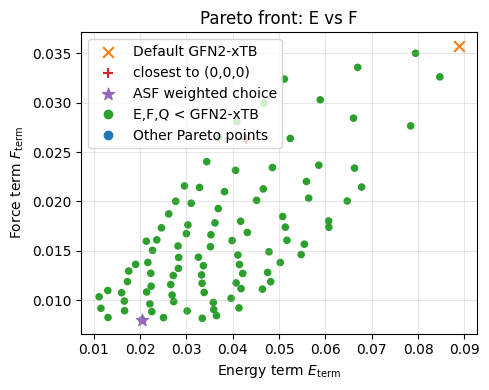

knee_selected_idx: 21
knee_objectives: [0.0428350093 0.0263347751 0.0292732667]
knee_params: [0.9493424588 1.0349931981 0.7407917828 0.2647605629 5.3805124542
 0.5315702053]

asf_selected_idx: 57
asf_objectives: [0.0204456521 0.0079764736 0.245128314 ]
asf_objectives / default: [0.2302942256 0.223169367 ]
asf_weights [E, F]: [0.01 0.99]
asf_value: 0.0010437249229127692
asf_params: [0.9178799761 1.0033829358 0.772467965  0.2175150483 5.376111753
 0.4133918872]


In [5]:
from matplotlib.lines import Line2D
E_term = F_pareto[:, 0]
F_term = F_pareto[:, 1]
try:
    Reg_term = F_pareto[:, 2]
except:
    Reg_term = None
E0 = 0.0887805676
F0 = 0.0357417941

better_mask = (
    (E_term <= E0) &
    (F_term <= F0) &
    ((E_term < E0) | (F_term < F0))
)

F_better = F_pareto[better_mask]
X_better = X_pareto[better_mask]

if len(F_better) == 0:
    raise ValueError("No Pareto points better than GFN2-xTB in all three objectives.")

dist2 = np.sum(F_better**2, axis=1)  # расстояние^2 до (0,0,0)
print(f'Number of Pareto points better than GFN2-xTB: {len(F_better)}')

knee_idx = np.argmin(dist2)
knee_params = X_better[knee_idx]
knee_objectives = F_better[knee_idx]
knee_selected_idx = np.where(better_mask)[0][knee_idx]


# ----------------------- ASF selection ----------------------- #
# Energy must improve / not worsen relative to default.
# Then ASF chooses a weighted compromise.
# Larger weights below mean "more important" in this implementation.
# Here: forces are most important, virials second, energies third.

mask = (
    (E_term <= E0) &
    (F_term <= F0) &
    ((E_term < E0) | (F_term < F0))
)

if Reg_term is not None:
    # 2. Регуляризация как constraint.
    # Если ты считаешь, что все Reg значения терпимые, оставь np.inf.
    R_max = np.inf


    mask = mask & (Reg_term <= R_max)

F_cand = F_pareto[mask]
X_cand = X_pareto[mask]
idx_cand = np.flatnonzero(mask)

if len(F_cand) == 0:
    raise ValueError("No candidates after E/Reg filtering.")

# 3. ASF только для E и F
weights = np.array([0.01, 0.99])  # E, F
weights = weights / weights.sum()

F_norm = F_cand[:, :2] / np.array([E0, F0])

ideal = np.min(F_norm, axis=0)

rho = 1e-6
delta = F_norm - ideal

asf_values = (
    np.max(weights * delta, axis=1)
    + rho * np.sum(weights * delta, axis=1)
)

j = np.argmin(asf_values)

asf_selected_idx = idx_cand[j]
asf_params = X_cand[j]
asf_objectives = F_cand[j]


colors = np.where(
    np.where(F_pareto[:, 0] < E0, True, False) *
    np.where(F_pareto[:, 1] < F0, True, False) == True,
    'tab:green',
    'tab:blue'
)

green_proxy = Line2D([0], [0], marker='o', linestyle='', color='tab:green', label='E,F,Q < GFN2')
blue_proxy = Line2D([0], [0], marker='o', linestyle='', color='tab:blue', label='Other Pareto points')


plt.figure(figsize=(5, 4))
plt.scatter(E_term, F_term, s=20, c=colors, label="_nolegend_")
plt.scatter([E0], [F0], s=60, marker="x", c='tab:orange', label="Default GFN2-xTB")
plt.scatter([knee_objectives[0]], [knee_objectives[1]], s=60, marker="+", c='tab:red', label="closest to (0,0,0)")
plt.scatter([asf_objectives[0]], [asf_objectives[1]], s=80, marker="*", c='tab:purple', label="ASF weighted choice")
plt.xlabel("Energy term $E_{\\text{term}}$")
plt.ylabel("Force term $F_{\\text{term}}$")
plt.title("Pareto front: E vs F")
plt.grid(True, alpha=0.3)
ax = plt.gca()
handles, labels = ax.get_legend_handles_labels()
handles.extend([green_proxy, blue_proxy])
labels.extend(['E,F,Q < GFN2-xTB', 'Other Pareto points'])
plt.legend(handles, labels)
plt.tight_layout()
plt.show()


print("knee_selected_idx:", knee_selected_idx)
print("knee_objectives:", knee_objectives)
print("knee_params:", knee_params)

print()
print("asf_selected_idx:", asf_selected_idx)
print("asf_objectives:", asf_objectives)
print("asf_objectives / default:", asf_objectives[:2] / np.array([E0, F0]))
print("asf_weights [E, F]:", weights)
print("asf_value:", asf_values[j])
print("asf_params:", asf_params)

In [6]:
# sorting by Regularization, filtering arep by not more then - 25% diff:
arep_idx = -1

# Оставляем точки, где arep уменьшился не более чем на 25%
idx_cand_filtered = [
    i for i in idx_cand
    if (
        (X_pareto[i, arep_idx] - default_gfn2_vector[arep_idx])
        / default_gfn2_vector[arep_idx]
        * 100
    ) >= -25
]

# Сортируем по Reg: от меньшего к большему
idx_cand_sorted = sorted(
    idx_cand_filtered,
    key=lambda i: F_pareto[i, 2],
)

for i in idx_cand_sorted:
    delta_percent = (
        (X_pareto[i] - default_gfn2_vector)
        / default_gfn2_vector
        * 100
    )

    print(
        f"Pareto point {i}: "
        f"E={F_pareto[i, 0]:.6f}, "
        f"F={F_pareto[i, 1]:.6f}, "
        f"Reg={F_pareto[i, 2]:.6f}"
    )
    print(
        f"Objectives / default: "
        f"E={F_pareto[i, 0] / E0:.6f}, "
        f"F={F_pareto[i, 1] / F0:.6f}"
    )
    print(f"Parameters: {X_pareto[i].tolist()}")
    print(f"Changes (%): {delta_percent}")
    print(f"arep change: {delta_percent[-1]:.2f}%")
    print()

Pareto point 93: E=0.079473, F=0.035010, Reg=0.002900
Objectives / default: E=0.895163, F=0.979535
Parameters: [0.9994523018501825, 1.0083472675315237, 0.7376482912977743, 0.27097513828743036, 5.32189534725135, 0.5700410284306161]
Changes (%): [-0.054769815   0.8347267532 -3.4222510598 -0.0298321058  1.4676752225
 -0.4691531703]
arep change: -0.47%

Pareto point 75: E=0.084711, F=0.032617, Reg=0.002954
Objectives / default: E=0.954166, F=0.912575
Parameters: [1.0, 0.999284079757596, 0.7605917294525845, 0.2710072380903015, 5.417277268276719, 0.5599646899809755]
Changes (%): [ 0.           -0.0715920242 -0.4183457623 -0.0179896072  3.28623443
 -2.2285116179]
arep change: -2.23%

Pareto point 63: E=0.066988, F=0.033578, Reg=0.004009
Objectives / default: E=0.754532, F=0.939456
Parameters: [0.975578646560824, 1.0165593267681052, 0.7654245686399722, 0.26849928647073207, 5.241520044347693, 0.5666699377903959]
Changes (%): [-2.4421353439  1.6559326768  0.2144012192 -0.9432418132 -0.0647666236

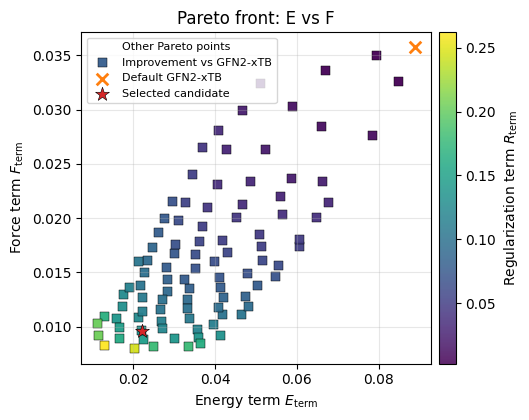

In [7]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

# ----------------------- Plot styling ----------------------- #

# Improvement marker:
# здесь я использую твой better_mask:
# E,F,Xi не хуже default, и хотя бы одна цель лучше.
improvement_mask = better_mask
other_mask = ~improvement_mask

# Color encodes regularization.
# Можно заменить "magma" на "viridis", "plasma", "cividis".
reg_cmap = "viridis"

reg_norm = Normalize(
    vmin=np.nanmin(Reg_term),
    vmax=np.nanmax(Reg_term),
)


def plot_pareto_with_reg_heatmap(
    x, y,
    x0, y0,
    knee_x, knee_y,
    asf_x, asf_y,
    xlabel, ylabel, title,
):
    fig, ax = plt.subplots(figsize=(5.4, 4.3))

    # Other Pareto points: circles
    sc = ax.scatter(
        x[other_mask],
        y[other_mask],
        c=Reg_term[other_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=24,
        marker="o",
        alpha=0.85,
        edgecolors="none",
        label="Other Pareto points",
    )

    # Improved solutions: squares
    ax.scatter(
        x[improvement_mask],
        y[improvement_mask],
        c=Reg_term[improvement_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=42,
        marker="s",
        alpha=0.95,
        edgecolors="black",
        linewidths=0.35,
        label=r"Improvement vs GFN2-xTB",
    )

    # Reference / selected points
    ax.scatter(
        [x0], [y0],
        s=70,
        marker="x",
        c="tab:orange",
        linewidths=2.0,
        label="Default GFN2-xTB",
        zorder=5,
    )


    ax.scatter(
        [asf_x], [asf_y],
        s=110,
        marker="*",
        c="tab:red",
        edgecolors="black",
        linewidths=0.4,
        label="Selected candidate",
        zorder=7,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label(r"Regularization term $R_{\mathrm{term}}$")

    ax.legend(fontsize=8, frameon=True)
    fig.tight_layout()
    plt.show()


# ----------------------- E vs F ----------------------- #
selected_idx = 26
selected_objectives = F_pareto[selected_idx]
plot_pareto_with_reg_heatmap(
    x=E_term,
    y=F_term,
    x0=E0,
    y0=F0,
    knee_x=knee_objectives[0],
    knee_y=knee_objectives[1],
    asf_x=selected_objectives[0],
    asf_y=selected_objectives[1],
    xlabel=r"Energy term $E_{\mathrm{term}}$",
    ylabel=r"Force term $F_{\mathrm{term}}$",
    title="Pareto front: E vs F",
)